# Fundamentos del análisis multivariante

Cuaderno del **Capítulo 1** de las notas del curso (*Notas de Clase: Análisis Multivariante*). Reproduce, paso a paso, los ejemplos numéricos del capítulo con el conjunto de datos de trabajo: cinco hogares con su ingreso ($x_1$) y su gasto ($x_2$) mensuales, en miles de pesos.

**Contenido**
1. Matriz de datos, vector de medias y matriz de centrado
2. Matrices de covarianzas y de correlaciones
3. Combinaciones lineales: el ahorro
4. Varianza total, varianza generalizada y eigenvalores
5. Distancia euclidiana contra distancia de Mahalanobis
6. La distribución normal multivariada: condicional y forma cuadrática
7. Autoevaluación
8. Ejercicio para el alumno

**Cómo usar este cuaderno.** Después de los resultados principales hay celdas **Lea la salida** con espacios `____` para completar, con el mismo formato que el quiz y el examen. Complételas *antes* de abrir la respuesta. Las celdas **Error común** muestran a propósito un análisis equivocado. Al final hay una autoevaluación.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
np.set_printoptions(suppress=True, precision=3)
pd.set_option("display.precision", 3)
AZUL, NARANJA, VERDE, TINTA = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#d9d8d4", "figure.dpi": 110})
from scipy import stats

## 1. Matriz de datos, vector de medias y matriz de centrado

$\bar{\mathbf{x}} = \frac{1}{n}\mathbf{X}'\mathbf{1}_n$ y $\mathbf{H} = \mathbf{I}_n - \frac{1}{n}\mathbf{1}_n\mathbf{1}_n'$.

In [2]:
X = np.array([[10, 9], [12, 10], [15, 12], [18, 16], [25, 18]], dtype=float)
n, p = X.shape
uno = np.ones(n)
xbar = X.T @ uno / n
H = np.eye(n) - np.outer(uno, uno) / n
HX = H @ X
print("x̄ =", xbar)
print("HX =\n", HX)
print("Columnas de HX suman:", HX.sum(axis=0))
print("H simétrica:", np.allclose(H, H.T), "| H idempotente:", np.allclose(H @ H, H), "| traza(H) =", np.trace(H))

x̄ = [16. 13.]
HX =
 [[-6. -4.]
 [-4. -3.]
 [-1. -1.]
 [ 2.  3.]
 [ 9.  5.]]
Columnas de HX suman: [0. 0.]
H simétrica: True | H idempotente: True | traza(H) = 4.0


## 2. Matrices de covarianzas y de correlaciones

$\mathbf{S} = \frac{1}{n}\mathbf{X}'\mathbf{H}\mathbf{X}$, $\mathbf{S}_u = \frac{n}{n-1}\mathbf{S}$ y $\mathbf{R} = \mathbf{D}^{-1/2}\mathbf{S}\mathbf{D}^{-1/2}$.

In [3]:
S = X.T @ H @ X / n
Su = S * n / (n - 1)
d = np.sqrt(np.diag(S))
R = S / np.outer(d, d)
print("S =\n", S); print("S_u =\n", Su); print("R =\n", R.round(4))
print("Coincide con np.cov(ddof=0):", np.allclose(S, np.cov(X.T, ddof=0)))

S =
 [[27.6 17.6]
 [17.6 12. ]]
S_u =
 [[34.5 22. ]
 [22.  15. ]]
R =
 [[1.    0.967]
 [0.967 1.   ]]
Coincide con np.cov(ddof=0): True


### Lea la salida

1. La correlación entre ingreso y gasto es `____`: una relación `____` (débil / fuerte) y `____` (positiva / negativa).
2. $\mathbf{S}_u$ es $\mathbf{S}$ multiplicada por $n/(n-1) =$ `____`.
3. Si se calcula $\mathbf{R}$ a partir de $\mathbf{S}_u$ en lugar de $\mathbf{S}$, ¿cambia? `____`, porque `____`.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

1. $r_{12} = 0.967$: fuerte y positiva. Los hogares que ganan más también gastan más.
2. $5/4 = 1.25$ (por ejemplo, $27.6 \times 1.25 = 34.5$).
3. No. El factor $n/(n-1)$ multiplica a la covarianza y a las dos varianzas, y se cancela en $r_{12} = s_{12}/\sqrt{s_{11}s_{22}}$.

</details>

### Error común: ¿divisor $n$ o $n-1$?

Las notas usan el divisor $n$. Las bibliotecas de Python no se ponen de acuerdo, y eso explica muchas diferencias pequeñas entre lo que usted obtiene y lo que dicen las notas.

In [4]:
print("np.cov, por omisión (ddof=1):\n", np.cov(X.T))
print("np.cov(ddof=0):\n", np.cov(X.T, ddof=0))
print("pandas .std() (ddof=1):", pd.DataFrame(X).std().values.round(3))
print("numpy .std()  (ddof=0):", X.std(axis=0).round(3))
from sklearn.preprocessing import StandardScaler
Zs = StandardScaler().fit_transform(X)      # divide entre la desviación estándar con divisor n
print("Z'Z/n con StandardScaler:\n", (Zs.T @ Zs / n).round(3))

np.cov, por omisión (ddof=1):
 [[34.5 22. ]
 [22.  15. ]]
np.cov(ddof=0):
 [[27.6 17.6]
 [17.6 12. ]]
pandas .std() (ddof=1): [5.874 3.873]
numpy .std()  (ddof=0): [5.254 3.464]


Z'Z/n con StandardScaler:
 [[1.    0.967]
 [0.967 1.   ]]


### Lea la salida

1. Devuelven cálculos con divisor $n$: `____`. Con divisor $n-1$: `____`.
2. ¿Cambia la matriz de correlaciones según el divisor? `____`.
3. Si un resultado suyo difiere del de las notas exactamente por un factor como $5/4$ o $150/149$, lo primero que revisaría es `____`.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

1. Divisor $n$: `np.cov(ddof=0)`, `.std()` de numpy y `StandardScaler`. Divisor $n-1$: `np.cov` por omisión y `.std()` (y `.cov()`) de pandas.
2. No: el factor se cancela (con `StandardScaler`, $\mathbf{Z}'\mathbf{Z}/n$ es exactamente $\mathbf{R}$).
3. El divisor que usa cada función.

</details>

## 3. Combinaciones lineales: el ahorro

El ahorro es $y = x_1 - x_2 = \mathbf{a}'\mathbf{x}$ con $\mathbf{a} = (1,-1)'$. Por la proposición de combinaciones lineales, $\bar y = \mathbf{a}'\bar{\mathbf{x}}$ y $s_y^2 = \mathbf{a}'\mathbf{S}\mathbf{a}$.

In [5]:
a = np.array([1, -1])
y = X @ a
print("Ahorros:", y)
print("Media directa:", y.mean(), "| a'x̄ =", a @ xbar)
print("Varianza directa:", y.var(), "| a'Sa =", a @ S @ a)

Ahorros: [1. 2. 3. 2. 7.]
Media directa: 3.0 | a'x̄ = 3.0
Varianza directa: 4.4 | a'Sa = 4.4


### Lea la salida

1. Con la proposición de combinaciones lineales: $s_y^2 = s_{11} + s_{22} - 2s_{12} =$ `____` $+$ `____` $- 2($`____`$) =$ `____`.
2. El ahorro varía mucho menos que el ingreso ($s_{11} = 27.6$) porque `____`.
3. Si ingreso y gasto no estuvieran correlacionados ($s_{12} = 0$), la varianza del ahorro sería `____`.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

1. $27.6 + 12 - 2(17.6) = 4.4$.
2. La covarianza es positiva y grande: el gasto acompaña al ingreso, así que en la diferencia ingreso − gasto esas variaciones comunes se cancelan.
3. $27.6 + 12 = 39.6$: nueve veces más. Ignorar la covarianza es el error más común con combinaciones lineales.

</details>

## 4. Varianza total, varianza generalizada y eigenvalores

In [6]:
lam, G = np.linalg.eigh(S)
lam, G = lam[::-1], G[:, ::-1]
print("Varianza total tr(S) =", np.trace(S), "| suma de eigenvalores =", lam.sum())
print("Varianza generalizada |S| =", np.linalg.det(S).round(4), "| producto de eigenvalores =", lam.prod().round(4))
print("Eigenvalores:", lam.round(3))
print("Proporción del primero:", (lam[0] / lam.sum()).round(4))
print("Primer eigenvector:", np.abs(G[:, 0]).round(3))

Varianza total tr(S) = 39.6 | suma de eigenvalores = 39.6
Varianza generalizada |S| = 21.44 | producto de eigenvalores = 21.44
Eigenvalores: [39.051  0.549]
Proporción del primero: 0.9861
Primer eigenvector: [0.838 0.545]


### Lea la salida

1. El primer eigenvalor explica `____` % de la varianza total.
2. Su eigenvector, $(0.838, 0.545)$, tiene los dos pesos `____` (del mismo signo / de signos opuestos): la dirección principal de los datos mide `____`.
3. El ingreso pesa más que el gasto porque `____`.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

1. $39.051/39.6 = 98.6\%$.
2. Del mismo signo (positivos): mide el nivel económico del hogar, porque ingreso y gasto se mueven juntos.
3. Su varianza (27.6) es mayor que la del gasto (12). Con $\mathbf{S}$, las variables con más varianza pesan más; en el capítulo 2 verá por qué esto obliga a decidir entre $\mathbf{S}$ y $\mathbf{R}$.

</details>

## 5. Distancia euclidiana contra distancia de Mahalanobis

Dos hogares nuevos: A $=(19,10)$ gana más y gasta menos que el promedio; B $=(19,16)$ gana y gasta más.

In [7]:
Sinv = np.linalg.inv(S)
for nombre, punto in [("A", [19, 10]), ("B", [19, 16])]:
    v = np.array(punto) - xbar
    print(f"Hogar {nombre}: euclidiana = {np.sqrt(v @ v):.2f} | Mahalanobis² = {v @ Sinv @ v:.2f}")

# Invariancia: ingreso en pesos, gasto en miles de pesos
C = np.diag([1000, 1])
Sc = C @ S @ C.T
for nombre, punto in [("A", [19, 10]), ("B", [19, 16])]:
    v = C @ (np.array(punto) - xbar)
    print(f"Hogar {nombre} (pesos): euclidiana = {np.sqrt(v @ v):.1f} | Mahalanobis² = {v @ np.linalg.inv(Sc) @ v:.2f}")

Hogar A: euclidiana = 4.24 | Mahalanobis² = 31.40
Hogar B: euclidiana = 4.24 | Mahalanobis² = 1.85
Hogar A (pesos): euclidiana = 3000.0 | Mahalanobis² = 31.40
Hogar B (pesos): euclidiana = 3000.0 | Mahalanobis² = 1.85


### Lea la salida

1. A y B están a la misma distancia euclidiana de la media: `____`.
2. Distancia de Mahalanobis al cuadrado: A = `____`, B = `____`. A es mucho más atípico porque `____`.
3. Al expresar el ingreso en pesos, la distancia euclidiana `____` (cambia / no cambia) y la de Mahalanobis `____`. Cuando las unidades son arbitrarias conviene usar `____`.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

1. 4.24 (miles de pesos).
2. A = 31.40 y B = 1.85. A gana más y gasta menos que el promedio: va contra la correlación positiva (0.967), una combinación que casi no aparece en la muestra. B gana y gasta más, como los demás hogares.
3. La euclidiana cambia (de 4.24 a 3000) y la de Mahalanobis no (31.40 y 1.85). Conviene Mahalanobis, que no depende de las unidades y toma en cuenta la correlación.

</details>

d²: [1.34 0.84 0.21 3.97 3.64] | suma = 10.0 = n·p = 10


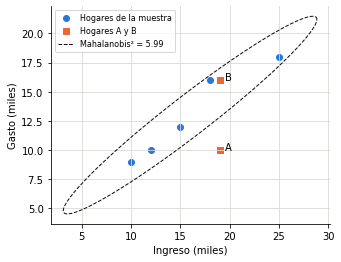

In [8]:
# Distancias de Mahalanobis de la muestra: su suma es n·p
d2 = np.einsum("ij,jk,ik->i", HX, Sinv, HX)
print("d²:", d2.round(2), "| suma =", d2.sum().round(6), "= n·p =", n * p)

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(X[:, 0], X[:, 1], color=AZUL, label="Hogares de la muestra")
ax.scatter([19, 19], [10, 16], color=NARANJA, marker="s", label="Hogares A y B")
for t, (u, w) in zip(["A", "B"], [(19, 10), (19, 16)]):
    ax.annotate(t, (u, w), xytext=(5, 0), textcoords="offset points")
# Elipse de Mahalanobis² = 5.99 (95% bajo normalidad)
th = np.linspace(0, 2 * np.pi, 200)
elipse = xbar[:, None] + np.linalg.cholesky(S) @ np.vstack([np.cos(th), np.sin(th)]) * np.sqrt(5.99)
ax.plot(*elipse, color=TINTA, lw=1, ls="--", label="Mahalanobis² = 5.99")
ax.set_xlabel("Ingreso (miles)"); ax.set_ylabel("Gasto (miles)"); ax.legend(fontsize=8)
plt.show()

## 6. Normal multivariada: condicional y forma cuadrática

Si (ingreso, gasto) $\sim N_2(\bar{\mathbf{x}}, \mathbf{S})$, entonces $\mathbb{E}[\text{gasto}\mid\text{ingreso}=x] = 13 + \frac{s_{12}}{s_{11}}(x-16)$ y $\text{Var}(\text{gasto}\mid\text{ingreso}) = s_{22} - s_{12}^2/s_{11}$.

In [9]:
pendiente = S[0, 1] / S[0, 0]
var_cond = S[1, 1] - S[0, 1] ** 2 / S[0, 0]
x0 = 25
media_cond = xbar[1] + pendiente * (x0 - xbar[0])
print(f"Pendiente (propensión marginal a gastar) = {pendiente:.3f}")
print(f"Varianza condicional = {var_cond:.3f} (reducción de {1 - var_cond / S[1, 1]:.1%} = r² = {R[0, 1]**2:.1%})")
print(f"Gasto esperado con ingreso 25: {media_cond:.2f}, IC95%: [{media_cond - 1.96*np.sqrt(var_cond):.2f}, {media_cond + 1.96*np.sqrt(var_cond):.2f}]")
# Forma cuadrática ~ chi2(2): P(chi2_2 > c) = exp(-c/2)
for nombre, d2_ in [("A", 31.40), ("B", 1.85)]:
    print(f"Hogar {nombre}: P(χ²₂ > {d2_}) = {stats.chi2.sf(d2_, 2):.2e}")

Pendiente (propensión marginal a gastar) = 0.638
Varianza condicional = 0.777 (reducción de 93.5% = r² = 93.5%)
Gasto esperado con ingreso 25: 18.74, IC95%: [17.01, 20.47]
Hogar A: P(χ²₂ > 31.4) = 1.52e-07
Hogar B: P(χ²₂ > 1.85) = 3.97e-01


### Lea la salida

1. Conocer el ingreso reduce la varianza del gasto en `____` %, que es igual a `____`.
2. Para un hogar con ingreso de 25 mil, el gasto esperado es `____` mil, con intervalo del 95 % de `____`.
3. Bajo normalidad, la probabilidad de observar un hogar al menos tan atípico como A es `____`; para B es `____`.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

1. 93.5 %, que es $r_{12}^2 = 0.967^2$.
2. 18.74 mil, con intervalo $[17.01,\ 20.47]$.
3. A: $1.5 \times 10^{-7}$, prácticamente imposible bajo el modelo: o es un hogar muy inusual o conviene revisar el dato. B: 0.40, un hogar común.

</details>

## 7. Autoevaluación

Dos reactivos con el formato del quiz y del examen: elija una opción y complete la justificación. No cuentan para la calificación.

**Reactivo 1.** Se agrega a la muestra un sexto hogar con ingreso de 30 mil y gasto de 10 mil. Sin recalcular, ¿qué ocurre con la correlación entre ingreso y gasto?

- (a) Aumenta, porque el nuevo hogar tiene el ingreso más alto de toda la muestra y amplía el rango de la variable.
- (b) Disminuye mucho, porque el nuevo hogar tiene ingreso alto y gasto bajo, en contra de la tendencia de los otros cinco.
- (c) No cambia, porque la correlación depende de las unidades de medida de las variables y no del número de hogares.
- (d) No cambia, porque un solo hogar no puede alterar de manera apreciable una correlación calculada con una muestra.

*Justificación:* el hogar 6 gana `____` (más / menos) que el promedio de los otros cinco y gasta `____`; eso va `____` (a favor / en contra) de la tendencia, así que la correlación `____`.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

**(b).** Gana más (30 contra 16) y gasta menos (10 contra 13): va en contra de la tendencia, así que la correlación baja, de 0.967 a 0.372. Con muestras pequeñas, un solo punto puede cambiar mucho una correlación, lo que descarta (d); (c) es falsa porque la correlación no depende de las unidades. Compruébelo con `np.corrcoef(np.vstack([X, [30, 10]]).T)`.

</details>

**Reactivo 2.** La varianza generalizada de los cinco hogares es $|\mathbf{S}| = 21.44$, mientras que $s_{11}s_{22} = 27.6 \times 12 = 331.2$. ¿Por qué $|\mathbf{S}|$ es tan pequeña?

- (a) Porque hay un error de cálculo: para dos variables cualesquiera, la varianza generalizada debe ser igual al producto $s_{11}s_{22}$.
- (b) Porque ingreso y gasto están muy correlacionados: $|\mathbf{S}| = s_{11}s_{22}(1 - r^2)$, y con $r^2 = 0.935$ la nube de puntos es una elipse delgada.
- (c) Porque la muestra tiene sólo cinco hogares; con una muestra más grande, $|\mathbf{S}|$ se acercaría al producto de las varianzas.
- (d) Porque las variables están en miles de pesos; si se midieran en pesos, la varianza generalizada sería igual a $s_{11}s_{22}$.

*Justificación:* $|\mathbf{S}| = s_{11}s_{22} - s_{12}^2 = 331.2 -$ `____` $=$ `____`. Factorizando, $|\mathbf{S}| = s_{11}s_{22}(1 - r^2)$ con $r^2 =$ `____`. Una $|\mathbf{S}|$ pequeña significa que `____`.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

**(b).** $331.2 - 17.6^2 = 331.2 - 309.76 = 21.44$, y $r^2 = 309.76/331.2 = 0.935$. Una varianza generalizada pequeña significa que los datos ocupan poco "volumen": casi toda la variación va en una sola dirección (el primer eigenvalor explica el 98.6 %). (a) sólo sería cierto con $r = 0$. (c) es falsa: $|\mathbf{S}|$ depende de la correlación, no de $n$. (d) es falsa: en pesos, $|\mathbf{S}|$ y $s_{11}s_{22}$ se multiplican por el mismo factor y su cociente, $1 - r^2$, no cambia.

</details>

## 8. Ejercicio para el alumno

Con la base `Country-data.csv` (carpeta `05 Clustering/04 Clustering Countries/`):
1. Calcule $\bar{\mathbf{x}}$, $\mathbf{S}$, $\mathbf{R}$, la varianza generalizada y las distancias de Mahalanobis.
2. Elabore la gráfica Q–Q ji-cuadrada e identifique los cinco países más atípicos.
3. ¿Cambia la lista si usa la distancia euclidiana estandarizada? Explique.

In [10]:
paises = pd.read_csv("../../05 Clustering/04 Clustering Countries/Country-data.csv", index_col="country")
paises.head()
# Su código aquí

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
country,,,,,,,,,
Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200
